# Classroom Intelligence & Behaviour Analysis System
### CNN + YOLOv8 Pose + Gradio | Google Colab

**Purpose:** analyse permitted classroom video at class level: estimate visible headcount, classify visible behaviour, estimate raised hands, and produce a downloadable analytical report.

> **Important limitations:** the public Human Action Recognition dataset is not classroom CCTV. Results are a workflow demonstration, not validated classroom measurements. The model does not identify students. Visual categories are not proof of attention, learning, or misconduct. Obtain informed permission, minimise retention, and follow applicable school policies and Kenya's Data Protection Act. Do not use outputs to punish or rank students.

### Improvements over the earlier notebook
- One clean stratified 70/15/15 split, created **before** training; no test-set leakage.
- Robust class filtering and checks for missing classes.
- MobileNetV2 transfer learning, early stopping, fine-tuning and class-weight support.
- Full held-out evaluation: accuracy, macro precision/recall/F1, per-class report and confusion matrix.
- Video inference uses the **trained behaviour CNN on person crops**, not an unrelated ImageNet ResNet classifier.
- Frame-level KPIs, confidence filtering, trend charts, annotated video and CSV export in Gradio.
- Clear handling of empty detections and unreadable video.

**Run cells from top to bottom.** Select a Colab T4 GPU under Runtime → Change runtime type for faster training.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Install dependencies

In [ ]:
!pip -q install datasets ultralytics gradio seaborn scikit-learn

## 2. Imports, reproducibility and device

In [ ]:
import os, random, warnings, math, tempfile
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_recall_fscore_support)
from ultralytics import YOLO
import gradio as gr

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
DEVICE = "GPU" if tf.config.list_physical_devices("GPU") else "CPU"
print("TensorFlow:", tf.__version__, "| Device:", DEVICE)
print("GPUs:", tf.config.list_physical_devices("GPU"))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
TensorFlow: 2.21.0 | Device: CPU
GPUs: []


## 3. Load and inspect the dataset

In [ ]:
DATASET_ID = "Bingsu/Human_Action_Recognition"
ds = load_dataset(DATASET_ID)
label_names = ds["train"].features["labels"].names
print(ds)
print("Available labels:", label_names)

KEEP = ["sitting", "sleeping", "texting", "using_laptop", "laughing"]
FRIENDLY = {
    "sitting": "Sitting (visual proxy)",
    "sleeping": "Sleeping-like",
    "texting": "Phone-use-like",
    "using_laptop": "Laptop-use-like",
    "laughing": "Social interaction-like"
}
CLASSES = [FRIENDLY[x] for x in KEEP]
keep_ids = {label_names.index(x) for x in KEEP}
train_raw = ds["train"].filter(lambda y: y in keep_ids, input_columns="labels")
print("Selected training images:", len(train_raw))
if len(train_raw) < 100:
    raise ValueError("Too few selected images. Check dataset labels or connectivity.")

class_counts = pd.Series([label_names[y] for y in train_raw["labels"]]).value_counts()
display(class_counts.rename(index=FRIENDLY).to_frame("images"))
if any(k not in class_counts.index for k in KEEP):
    raise ValueError("At least one selected class is missing. Revise KEEP before training.")

README.md:   0%|          | 0.00/4.70k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  229MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 98.1MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

DatasetDict({
    train: Dataset({
        features: ['image', 'labels'],
        num_rows: 12600
    })
    test: Dataset({
        features: ['image', 'labels'],
        num_rows: 5400
    })
})
Available labels: ['calling', 'clapping', 'cycling', 'dancing', 'drinking', 'eating', 'fighting', 'hugging', 'laughing', 'listening_to_music', 'running', 'sitting', 'sleeping', 'texting', 'using_laptop']


Filter:   0%|          | 0/12600 [00:00<?, ? examples/s]

Selected training images: 4200


,images
Sitting (visual proxy),840
Laptop-use-like,840
Sleeping-like,840
Social interaction-like,840
Phone-use-like,840


## 4. Exploratory data analysis

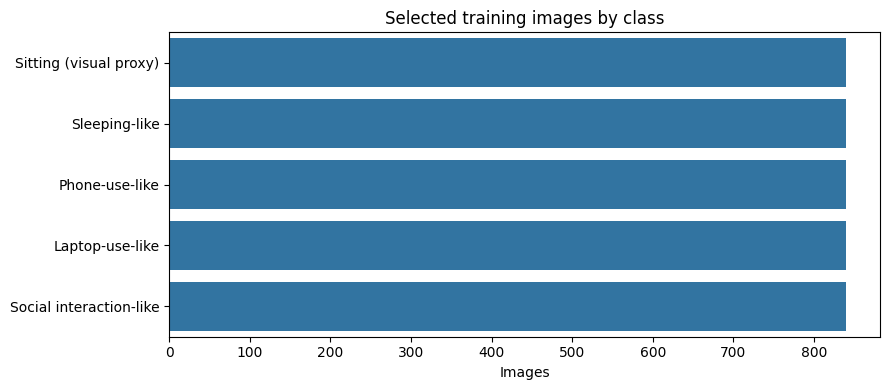

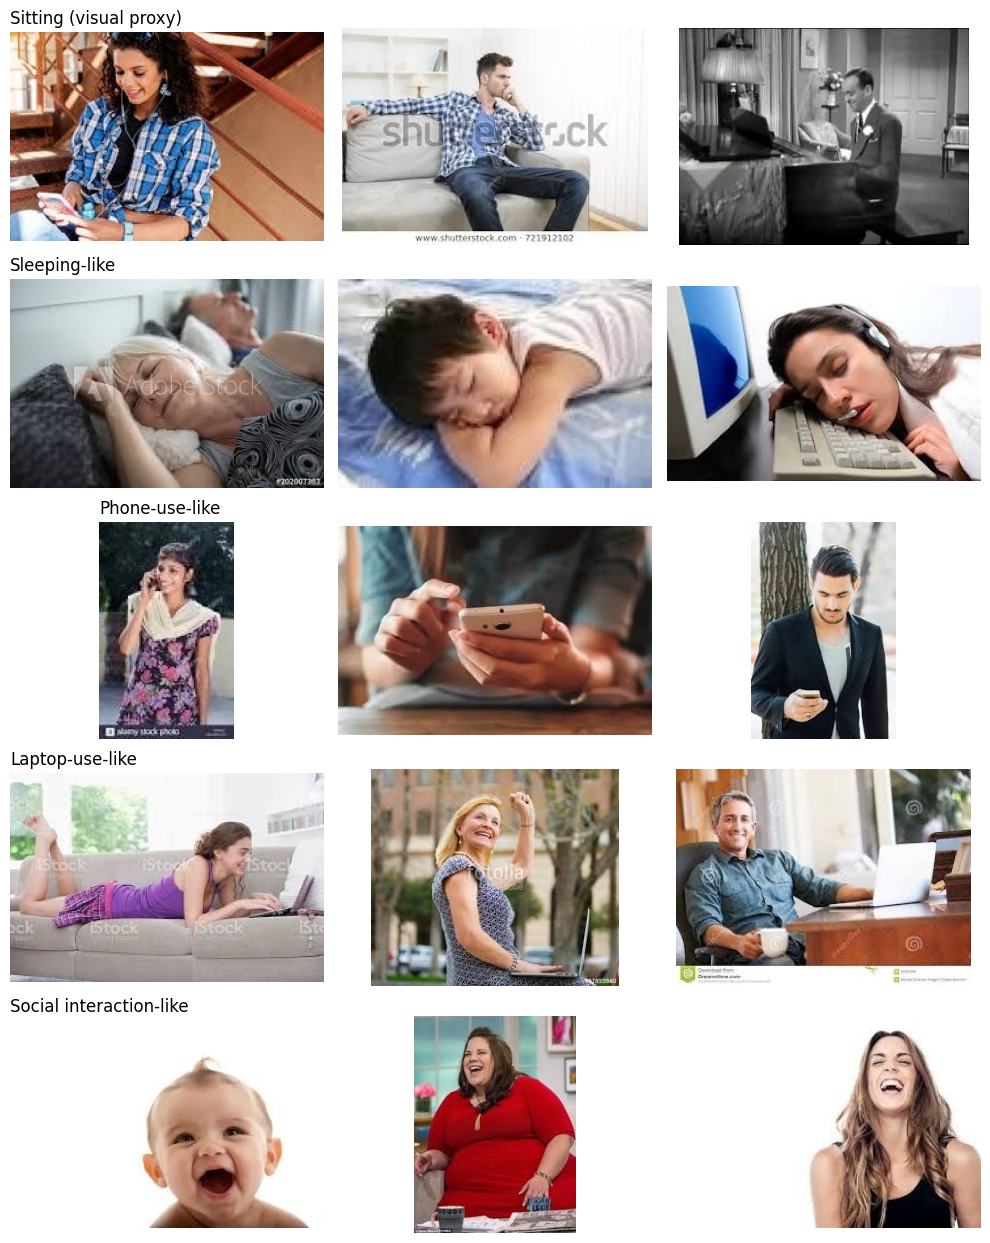

In [ ]:
counts = pd.Series([FRIENDLY[label_names[y]] for y in train_raw["labels"]]).value_counts().reindex(CLASSES)
plt.figure(figsize=(9,4))
sns.barplot(x=counts.values, y=counts.index)
plt.title("Selected training images by class"); plt.xlabel("Images"); plt.ylabel("")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(len(KEEP), 3, figsize=(10, 2.5*len(KEEP)))
for r, raw_name in enumerate(KEEP):
    idxs = [i for i, y in enumerate(train_raw["labels"]) if label_names[y] == raw_name][:3]
    for c in range(3):
        axes[r,c].axis("off")
        if c < len(idxs):
            axes[r,c].imshow(train_raw[idxs[c]]["image"].convert("RGB"))
            if c == 0: axes[r,c].set_title(FRIENDLY[raw_name], loc="left")
plt.tight_layout(); plt.show()

## 5. Prepare images and create leakage-safe splits

In [ ]:
IMG_SIZE = 160
def to_arrays(split):
    X = np.empty((len(split), IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    y = np.empty((len(split),), dtype=np.int32)
    for i, ex in enumerate(split):
        im = ex["image"].convert("RGB").resize((IMG_SIZE, IMG_SIZE))
        X[i] = np.asarray(im)
        y[i] = KEEP.index(label_names[ex["labels"]])
    return X, y

X_all, y_all = to_arrays(train_raw)
# Split once, before fitting anything: 70% train, 15% validation, 15% test.
X_train, X_temp, y_train, y_temp = train_test_split(
    X_all, y_all, test_size=0.30, stratify=y_all, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

print("Train:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)
for name, yy in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(name, pd.Series(yy).value_counts(normalize=True).sort_index().round(3).to_dict())

Train: (2940, 160, 160, 3) Validation: (630, 160, 160, 3) Test: (630, 160, 160, 3)
Train {0: 0.2, 1: 0.2, 2: 0.2, 3: 0.2, 4: 0.2}
Validation {0: 0.2, 1: 0.2, 2: 0.2, 3: 0.2, 4: 0.2}
Test {0: 0.2, 1: 0.2, 2: 0.2, 3: 0.2, 4: 0.2}


## 6. Build a transfer-learning CNN

In [ ]:

# BUILD IMPROVED CNN MODEL — KERAS 3 COMPATIBLE

augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.06),
    layers.RandomZoom(0.10),
], name="augmentation")

# Load pretrained MobileNetV2
backbone = keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

backbone.trainable = False

# Build CNN
inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

# Data augmentation
x = augment(inputs)

# MobileNetV2 preprocessing: [0,255] -> [-1,1]
# Keras layer avoids the KerasTensor compatibility error.
x = layers.Rescaling(
    scale=1./127.5,
    offset=-1,
    name="mobilenet_preprocessing"
)(x)

# Extract image features
x = backbone(x, training=False)

# Classification head
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.35)(x)

outputs = layers.Dense(
    len(CLASSES),
    activation="softmax",
    name="behaviour_predictions"
)(x)

model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="classroom_behaviour_mobilenetv2"
)

# Compile
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "classroom_behaviour_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_preprocessing         │ (None, 160, 160, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ behaviour_predictions (Dense)   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,269,509 (8.66 MB)

 Trainable params: 8,965 (35.02 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

## 7. Train, monitor and fine-tune

In [ ]:
weights = compute_class_weight(class_weight="balanced",
                               classes=np.unique(y_train), y=y_train)
class_weights = {i: float(w) for i, w in enumerate(weights)}
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                  restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3,
                                      patience=2, min_lr=1e-6)
]
hist1 = model.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=10, batch_size=32, class_weight=class_weights,
    callbacks=callbacks, verbose=1)

# Fine-tune only the last 30 backbone layers, keeping BatchNorm frozen.
backbone.trainable = True
for layer in backbone.layers[:-30]:
    layer.trainable = False
for layer in backbone.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist2 = model.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=6, batch_size=32, class_weight=class_weights,
    callbacks=callbacks, verbose=1)

Epoch 1/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 102s 1s/step - accuracy: 0.4850 - loss: 1.5183 - val_accuracy: 0.7206 - val_loss: 0.7779 - learning_rate: 0.0010
Epoch 2/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 93s 1s/step - accuracy: 0.6561 - loss: 1.0213 - val_accuracy: 0.7492 - val_loss: 0.6969 - learning_rate: 0.0010
Epoch 3/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 141s 996ms/step - accuracy: 0.6905 - loss: 0.9061 - val_accuracy: 0.7651 - val_loss: 0.6851 - learning_rate: 0.0010
Epoch 4/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 100s 1s/step - accuracy: 0.7054 - loss: 0.8295 - val_accuracy: 0.7857 - val_loss: 0.6602 - learning_rate: 0.0010
Epoch 5/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 93s 1s/step - accuracy: 0.7272 - loss: 0.7910 - val_accuracy: 0.7810 - val_loss: 0.6629 - learning_rate: 0.0010
Epoch 6/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 93s 1s/step - accuracy: 0.7235 - loss: 0.7438 - val_accuracy: 0.7905 - val_loss: 0.6466 - learning_rate: 0.0010
Epoch 7/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 150s 1s/step - accuracy: 0.7350 - loss: 0.7383 - val_acc

## 8. Training diagnostics

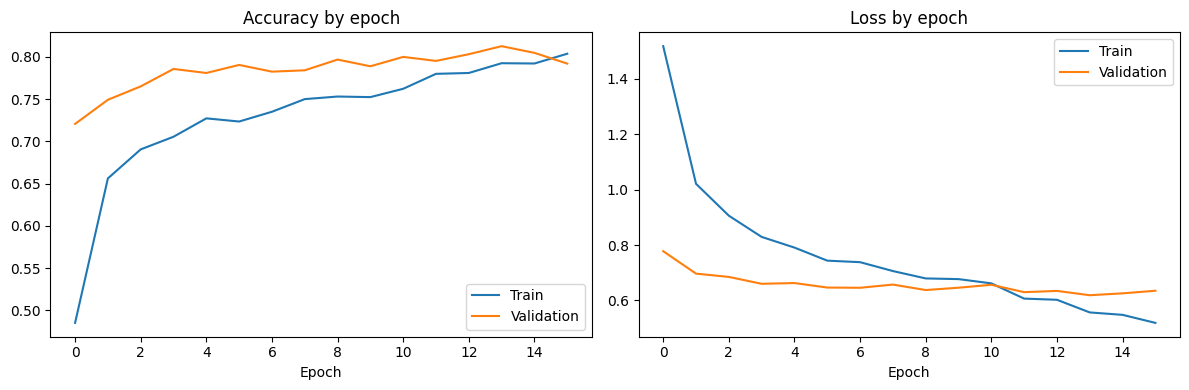

In [ ]:
def combine_history(key):
    return hist1.history.get(key, []) + hist2.history.get(key, [])

fig, ax = plt.subplots(1,2,figsize=(12,4))
ax[0].plot(combine_history("accuracy"), label="Train")
ax[0].plot(combine_history("val_accuracy"), label="Validation")
ax[0].set_title("Accuracy by epoch"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(combine_history("loss"), label="Train")
ax[1].plot(combine_history("val_loss"), label="Validation")
ax[1].set_title("Loss by epoch"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

## 9. Final evaluation on untouched test set

Test accuracy: 0.757 | Test loss: 0.732
                         precision    recall  f1-score   support

 Sitting (visual proxy)       0.75      0.70      0.72       126
          Sleeping-like       0.77      0.83      0.80       126
         Phone-use-like       0.73      0.60      0.66       126
        Laptop-use-like       0.75      0.80      0.77       126
Social interaction-like       0.79      0.86      0.82       126

               accuracy                           0.76       630
              macro avg       0.76      0.76      0.75       630
           weighted avg       0.76      0.76      0.75       630



,Class,Precision,Recall,F1-score,Support
0,Sitting (visual proxy),0.746,0.698,0.721,126
1,Sleeping-like,0.766,0.833,0.798,126
2,Phone-use-like,0.728,0.595,0.655,126
3,Laptop-use-like,0.748,0.802,0.774,126
4,Social interaction-like,0.788,0.857,0.821,126


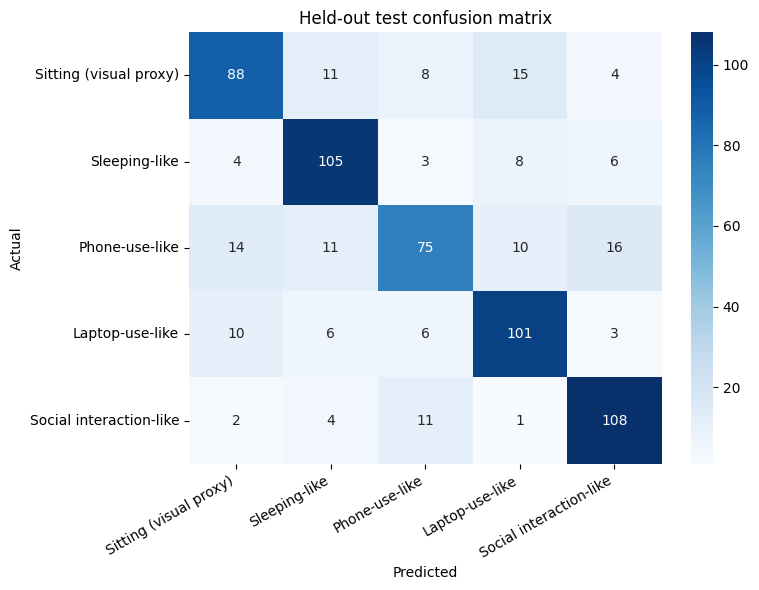

In [ ]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
probs_test = model.predict(X_test, batch_size=32, verbose=0)
pred_test = probs_test.argmax(axis=1)
p, r, f1, support = precision_recall_fscore_support(
    y_test, pred_test, labels=np.arange(len(CLASSES)), zero_division=0)
print(f"Test accuracy: {test_acc:.3f} | Test loss: {test_loss:.3f}")
print(classification_report(y_test, pred_test, target_names=CLASSES, zero_division=0))
metrics_df = pd.DataFrame({"Class": CLASSES, "Precision": p, "Recall": r,
                           "F1-score": f1, "Support": support})
display(metrics_df.round(3))
cm = confusion_matrix(y_test, pred_test, labels=np.arange(len(CLASSES)))
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Held-out test confusion matrix")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

## 10. Inspect incorrect and uncertain predictions

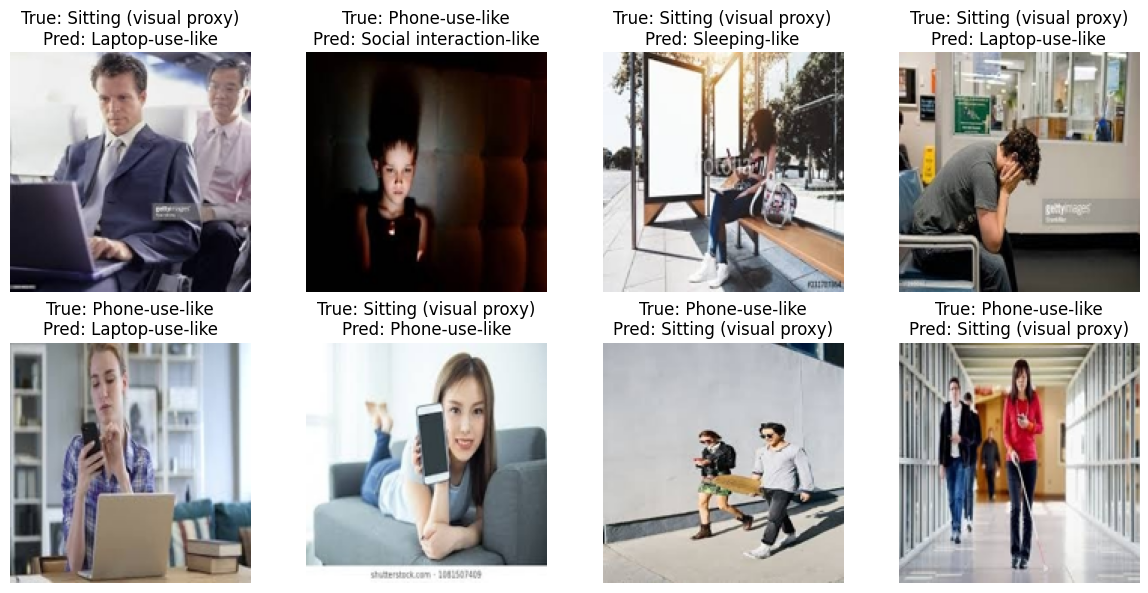

Mean confidence: 0.837
Predictions below 0.50 confidence: 41


In [ ]:
wrong = np.where(pred_test != y_test)[0]
if len(wrong):
    rng = np.random.default_rng(SEED)
    chosen = rng.choice(wrong, size=min(8, len(wrong)), replace=False)
    fig, axes = plt.subplots(2,4,figsize=(12,6))
    for ax, i in zip(axes.ravel(), chosen):
        ax.imshow(X_test[i]); ax.axis("off")
        ax.set_title(f"True: {CLASSES[y_test[i]]}\nPred: {CLASSES[pred_test[i]]}")
    for ax in axes.ravel()[len(chosen):]: ax.axis("off")
    plt.tight_layout(); plt.show()
else:
    print("No incorrect predictions in this test sample.")

test_conf = probs_test.max(axis=1)
print("Mean confidence:", round(float(test_conf.mean()),3))
print("Predictions below 0.50 confidence:", int((test_conf < 0.50).sum()))

## 11. Save the trained CNN and load YOLO pose

In [ ]:
MODEL_PATH = "/content/classroom_behaviour_cnn.keras"
model.save(MODEL_PATH)
print("Saved:", MODEL_PATH)

# YOLOv8 pose estimates people and 17 COCO body keypoints.
pose_model = YOLO("yolov8n-pose.pt")
L_SHOULDER, R_SHOULDER, L_WRIST, R_WRIST = 5, 6, 9, 10

def hand_is_raised(kpts, min_conf=0.5, margin_px=10):
    # Keypoints are [x, y, confidence]. A wrist must be clearly above its shoulder.
    for wrist, shoulder in [(L_WRIST,L_SHOULDER),(R_WRIST,R_SHOULDER)]:
        wx, wy, wc = kpts[wrist]
        sx, sy, sc = kpts[shoulder]
        if wc >= min_conf and sc >= min_conf and wy < sy - margin_px:
            return True
    return False

Saved: /content/classroom_behaviour_cnn.keras


## 12. Person-level inference: YOLO + the trained CNN

In [ ]:
BEHAVIOUR_COLORS = {
    CLASSES[0]:(60,180,75), CLASSES[1]:(230,25,75),
    CLASSES[2]:(245,130,48), CLASSES[3]:(0,130,200),
    CLASSES[4]:(145,30,180)
}
BEHAVIOUR_THRESHOLD = 0.50

def analyze_frame(frame_bgr, det_conf=0.35):
    result = pose_model(frame_bgr, verbose=False, conf=det_conf)[0]
    detections = []
    if result.boxes is None or len(result.boxes) == 0 or result.keypoints is None:
        return detections
    boxes = result.boxes.xyxy.cpu().numpy().astype(int)
    kpts_all = result.keypoints.data.cpu().numpy()
    h, w = frame_bgr.shape[:2]
    for box, kpts in zip(boxes, kpts_all):
        x1,y1,x2,y2 = box
        x1,x2 = int(np.clip(x1,0,w)), int(np.clip(x2,0,w))
        y1,y2 = int(np.clip(y1,0,h)), int(np.clip(y2,0,h))
        if x2-x1 < 24 or y2-y1 < 24: continue
        crop = frame_bgr[y1:y2, x1:x2]
        crop_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
        crop_rgb = cv2.resize(crop_rgb, (IMG_SIZE,IMG_SIZE)).astype("float32")
        probs = model.predict(crop_rgb[None,...], verbose=0)[0]
        idx = int(np.argmax(probs)); confidence = float(probs[idx])
        detections.append({
            "box":(x1,y1,x2,y2), "behaviour":CLASSES[idx],
            "confidence":confidence,
            "low_confidence":confidence < BEHAVIOUR_THRESHOLD,
            "hand_raised":hand_is_raised(kpts)
        })
    return detections

def draw_detections(frame_bgr, detections):
    out = frame_bgr.copy()
    for d in detections:
        x1,y1,x2,y2 = d["box"]
        color = BEHAVIOUR_COLORS[d["behaviour"]]
        label = f'{d["behaviour"]} {d["confidence"]:.0%}'
        if d["hand_raised"]: label += " | HAND UP"
        if d["low_confidence"]: label += " | LOW CONF"
        cv2.rectangle(out,(x1,y1),(x2,y2),color,2)
        cv2.putText(out,label,(x1,max(20,y1-7)),cv2.FONT_HERSHEY_SIMPLEX,
                    0.48,color,2,cv2.LINE_AA)
    cv2.putText(out,f"Visible people: {len(detections)}",(15,30),
                cv2.FONT_HERSHEY_SIMPLEX,0.85,(255,255,255),2)
    return out

## 13. Video analysis engine

In [ ]:
def analyze_video_file(video_path, sample_every_sec=2.0, max_frames=180,
                       behaviour_threshold=0.50, progress=gr.Progress()):
    if not video_path or not os.path.exists(video_path):
        raise gr.Error("Please upload a readable video.")
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise gr.Error("Could not open this video. Try an MP4 file.")
    fps = cap.get(cv2.CAP_PROP_FPS)
    if not fps or fps <= 0: fps = 25.0
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT) or 0)
    duration = total_frames / fps if total_frames else 0
    stride = max(1, int(round(fps * float(sample_every_sec))))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    if width <= 0 or height <= 0:
        cap.release(); raise gr.Error("Video dimensions could not be read.")

    output_path = os.path.join(tempfile.gettempdir(), "classroom_analysis_annotated.mp4")
    writer = cv2.VideoWriter(output_path, cv2.VideoWriter_fourcc(*"mp4v"),
                             max(1.0, fps/stride), (width,height))
    rows, frame_rows = [], []
    frame_idx = 0; sampled = 0
    while sampled < int(max_frames):
        ok, frame = cap.read()
        if not ok: break
        if frame_idx % stride == 0:
            timestamp = frame_idx / fps
            detections = analyze_frame(frame)
            annotated = draw_detections(frame,detections)
            writer.write(annotated)
            frame_rows.append({"time_sec":timestamp,"present":len(detections),
                               "raised_hands":sum(d["hand_raised"] for d in detections)})
            for d in detections:
                rows.append({"time_sec":timestamp,"present":len(detections),
                    "behaviour":d["behaviour"],"confidence":d["confidence"],
                    "low_confidence":d["low_confidence"],
                    "hand_raised":d["hand_raised"]})
            sampled += 1
            progress(min(0.99, sampled/max(1,min(max_frames,math.ceil(total_frames/stride)))),
                     desc=f"Analysing sampled frame {sampled}")
        frame_idx += 1
    cap.release(); writer.release()
    if sampled == 0:
        raise gr.Error("No frames were sampled from this video.")

    detections_df = pd.DataFrame(rows, columns=["time_sec","present","behaviour",
        "confidence","low_confidence","hand_raised"])
    frames_df = pd.DataFrame(frame_rows)
    valid = detections_df[detections_df["confidence"] >= float(behaviour_threshold)].copy()
    behaviour_counts = valid["behaviour"].value_counts()
    behaviour_share = (valid["behaviour"].value_counts(normalize=True)*100).round(1)
    attendance_median = float(frames_df["present"].median())
    attendance_peak = int(frames_df["present"].max())
    total_hands = int(frames_df["raised_hands"].sum())
    engagement = (100*valid["behaviour"].isin([CLASSES[0],CLASSES[3]]).mean()
                  if len(valid) else 0.0)
    # Explicitly label this as a heuristic, not a measure of learning.
    summary = f'''
### Analysis summary
- **Sampled frames:** {sampled}
- **Video duration:** {duration:.1f} seconds (if metadata available)
- **Estimated visible headcount (median):** {attendance_median:.1f}
- **Peak visible headcount:** {attendance_peak}
- **Raised-hand detections:** {total_hands}
- **Behaviour detections above confidence threshold:** {len(valid)} / {len(detections_df)}
- **Heuristic engaged-category share:** {engagement:.1f}%

*The engaged-category share counts only the visual categories "{CLASSES[0]}" and "{CLASSES[3]}". It is not a validated engagement or learning score.*
'''
    # Save report files
    csv_path = os.path.join(tempfile.gettempdir(),"classroom_detections.csv")
    summary_path = os.path.join(tempfile.gettempdir(),"classroom_summary.csv")
    detections_df.to_csv(csv_path,index=False)
    pd.DataFrame({"Metric":["Median visible headcount","Peak visible headcount",
        "Raised-hand detections","Heuristic engaged-category share (%)",
        "Confident behaviour detections"],
        "Value":[round(attendance_median,2),attendance_peak,total_hands,
                 round(engagement,2),len(valid)]}).to_csv(summary_path,index=False)


    # Create the four-panel analytics dashboard
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))

    # 1. Visible headcount
    axes[0, 0].plot(
        frames_df["time_sec"],
        frames_df["present"],
        marker="o",
        color="#3B82F6",
        label="Visible people"
    )
    axes[0, 0].set_title("Visible Headcount Over Time")
    axes[0, 0].set_xlabel("Time (seconds)")
    axes[0, 0].set_ylabel("People detected")
    axes[0, 0].legend()

    # 2. Raised hands
    axes[0, 1].plot(
        frames_df["time_sec"],
        frames_df["raised_hands"],
        marker="o",
        color="#22C55E",
        label="Raised hands"
    )
    axes[0, 1].set_title("Raised-Hand Detections Over Time")
    axes[0, 1].set_xlabel("Time (seconds)")
    axes[0, 1].set_ylabel("Detections")
    axes[0, 1].legend()

    # 3. Behaviour distribution
    if len(behaviour_share):
        axes[1, 0].barh(
            behaviour_share.index,
            behaviour_share.values,
            color="#6366F1",
            label="Behaviour share"
        )

    axes[1, 0].set_title("Behaviour Distribution")
    axes[1, 0].set_xlabel("Share (%)")
    if len(behaviour_share):
        axes[1, 0].legend()

    # 4. Behaviour trends with colour-coded legend
    if len(valid):
        timeline = valid.groupby([
            pd.cut(
                valid["time_sec"],
                bins=min(10, max(1, valid["time_sec"].nunique())),
                duplicates="drop"
            ),
            "behaviour"
        ]).size().unstack(fill_value=0)

        behaviour_colours = {
            "sitting": "#3B82F6",
            "sleeping": "#EF4444",
            "texting": "#F59E0B",
            "using_laptop": "#22C55E",
            "laughing": "#A855F7"
        }

        timeline.plot(
            kind="bar",
            stacked=True,
            ax=axes[1, 1],
            color=[
                behaviour_colours.get(str(c).lower(), "#64748B")
                for c in timeline.columns
            ]
        )

        axes[1, 1].legend(
            title="Behaviour Categories",
            loc="upper left",
            bbox_to_anchor=(1.02, 1),
            fontsize=8
        )

    axes[1, 1].set_title("Behaviour Trends Over Time")
    axes[1, 1].set_xlabel("Time Interval")
    axes[1, 1].set_ylabel("Number of detections")
    axes[1, 1].tick_params(axis="x", rotation=35)

    fig.tight_layout()

    return summary, fig, detections_df.head(100), output_path, csv_path, summary_path

## 14. Launch the interactive Gradio dashboard

In [ ]:
with gr.Blocks(theme=gr.themes.Soft(), title="Class is in session") as app:
    gr.Markdown("# 🎓 Classroom Intel")
    gr.Markdown("Upload permitted classroom footage to generate class-level visual estimates. No identity recognition is performed.")
    with gr.Row():
        with gr.Column(scale=1):
            video_input = gr.Video(label="Upload classroom video")
            sample_seconds = gr.Slider(0.5,10, value=2, step=0.5,
                                       label="Sample one frame every (seconds)")
            max_frames_input = gr.Slider(10,300,value=120,step=10,
                                         label="Maximum sampled frames")
            conf_input = gr.Slider(0.30,0.90,value=0.50,step=0.05,
                                   label="Minimum behaviour confidence")
            run_btn = gr.Button("Analyse classroom video", variant="primary")
        with gr.Column(scale=1):
            summary_out = gr.Markdown(label="Key findings")
            gr.Markdown("**Interpretation note:** headcount can undercount occluded people; hand raises can be confused with other gestures; visual behaviour labels are uncertain proxies.")
    charts_out = gr.Plot(label="Classroom analytics")
    with gr.Row():
        video_out = gr.Video(label="Annotated sampled video")
        table_out = gr.Dataframe(label="Person-level detections", interactive=False)
    with gr.Row():
        csv_out = gr.File(label="Download detection-level CSV")
        summary_csv_out = gr.File(label="Download summary CSV")
    run_btn.click(fn=analyze_video_file,
        inputs=[video_input,sample_seconds,max_frames_input,conf_input],
        outputs=[summary_out,charts_out,table_out,video_out,csv_out,summary_csv_out])


app.queue().launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://b3a2b0d77fe4ccbc51.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 15. Export model and evaluation artifacts
Run this cell after training if you want to download the model and evaluation report.

In [ ]:
model.save("/content/classroom_behaviour_cnn.keras")
metrics_df.to_csv("/content/classification_metrics.csv", index=False)
print("Saved model and classification metrics.")
try:
    from google.colab import files
    files.download("/content/classroom_behaviour_cnn.keras")
    files.download("/content/classification_metrics.csv")
except Exception as e:
    print("Download from the Colab Files panel:", e)

## 16. Methodology, interpretation and limitations

1. **Dataset mismatch:** the selected public action images are not classroom CCTV. Camera height, distance, occlusion, lighting, uniforms and classroom layouts can substantially reduce real-world performance.
2. **Training labels:** the five output categories are visual proxies. "Sitting" does not prove attentiveness; laptop use does not prove schoolwork; laughing does not prove disruption.
3. **Person-crop domain shift:** the CNN is trained on action photographs and applied to YOLO person crops. Fine-tuning on consented, locally labelled crops is required before claiming classroom validity.
4. **Attendance:** the system estimates the number of visible people in sampled frames. It does not identify unique students or establish official attendance.
5. **Raised hands:** wrist-above-shoulder is a simple geometric heuristic. It can mistake stretching or other gestures for participation. Requiring persistence across multiple consecutive samples can reduce noise.
6. **Temporal sampling:** sampled frames are snapshots, not continuous tracking. Repeated detections across frames are not unique people.
7. **Evaluation:** the held-out test score measures performance on the selected public dataset only. It must not be presented as accuracy on actual classroom CCTV.
8. **Next research steps:** collect appropriately consented classroom examples, label consistently, compare EfficientNetB0 with MobileNetV2, calibrate confidence, evaluate by lighting/distance/occlusion, and test on a separate classroom/site.

### Suggested project conclusion
The system demonstrates an end-to-end computer-vision workflow integrating transfer learning, object detection, pose estimation, video processing and interactive analytics. Its current outputs are exploratory class-level indicators. Further domain-specific data collection and validation are necessary before operational deployment.